# 00 — Veri Seti ve Keşifsel Veri Analizi (EDA)

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Bu notebook, kitaptaki bütün makine öğrenmesi uygulamalarının temelini oluşturan
veri setini tanıtır. İncelemenin her adımı, kitap metnindeki sayıların doğrudan
kaynağıdır; hesaplanan değerler en sonda `sonuclar/_veri_ozeti.json` dosyasına yazılır.

In [1]:
import ortak as o
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = o.veri_yukle()
EK = {}          # kitap metnine aktarılacak ek sayılar
print("Nokta sayısı        :", len(df))
print("Özellikler (16)     :", o.OZELLIKLER)
print("İklim grubu sayısı  :", df[o.GRUP].nunique())
df[["Nokta_No", "Yangin", "Baki", "Arazi", "NDVI", "Egim", "Yukseklik", "Sicaklik",
    "Yagis", "Ruzgar_Hizi", "Yol_Uzaklik", "Yerlesim_Uzaklik", "Sinif"]].head(8)

6410 nokta · yangın 3144 · yangın yok 3266
Nokta sayısı        : 6410
Özellikler (16)     : ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
İklim grubu sayısı  : 25


,Nokta_No,Yangin,Baki,Arazi,NDVI,Egim,Yukseklik,Sicaklik,Yagis,Ruzgar_Hizi,Yol_Uzaklik,Yerlesim_Uzaklik,Sinif
0,1,1,Düz,Tarım,0.274741,0.000000,16.000000,19.13671,101.10270,1.985137,72.404543,341.064792,Yangın
1,2,1,Düz,Tarım,0.097535,0.000000,328.982200,16.68583,49.10944,1.688260,214.293189,3204.075548,Yangın
2,3,1,Düz,Tarım,0.118961,0.000000,6.000000,17.82831,52.20567,1.716142,74.094309,408.695148,Yangın
3,4,1,Doğu,Yerleşim,0.100288,0.372233,3.000000,18.92697,88.27003,2.888625,30.619806,83.387360,Yangın
4,5,1,Kuzeybatı,Tarım,0.322840,0.372233,6.030597,19.04383,87.37311,2.215718,133.770926,248.464281,Yangın
5,6,1,Kuzey,Tarım,0.239704,0.372233,5.905493,19.02674,73.91023,2.153053,347.849212,479.849412,Yangın
6,7,1,Kuzey,Tarım,0.137894,0.372233,18.665390,19.36422,98.27899,2.269851,29.421317,3.256806,Yangın
7,8,1,Güneybatı,Orman,0.128258,0.372233,145.328000,17.87529,61.93587,1.426053,149.581803,1173.718254,Yangın


## 1. Kaynağı ve Temizlik Adımlarını Doğrulama

Veri seti, Mendeley Data deposunda CC BY 4.0 lisansıyla yayımlanan **"Forest fire and
non-fire sample points with eleven conditioning factors for Muğla, Türkiye (2015–2024)"**
veri setidir (Eriş, 2026; doi:10.17632/mjz29dh3g8.1). Yangın kayıtları Muğla Orman Bölge
Müdürlüğü'ne aittir. Dosya, depo API'sinden indirilmiş ve SHA-256 özetiyle doğrulanmıştır
(`_builder/veri_indir.py`); temizlik adımları `_builder/veri_hazirla.py` dosyasındadır.
Aşağıdaki hücre, temizlik adımlarının sayısal dökümünü okur.

**Önemli bir kaynak sınırlılığı:** Veri setinde noktaların coğrafi koordinatları yoktur.
Bu nedenle gerçek mekânsal doğrulama yapılamaz; bunun yerine iklim yüzeylerinden türetilmiş
**sözde mekânsal gruplar** kullanılır (Bölüm 7).

In [2]:
with open(o.TEMIZLIK_YOLU, encoding="utf-8") as f:
    tem = json.load(f)
print(o.KAYNAK); print("doi:" + o.KAYNAK_DOI); print(o.KAYNAK_URL)
print()
print(f"Ham satır                          : {tem['ham_satir']} "
      f"(yangın {tem['ham_sinif']['yangin']}, yangın değil {tem['ham_sinif']['yangin_degil']})")
print(f"Ham özellik (etken) sayısı         : {tem['ham_ozellik_sayisi']}")
print(f"Ham dosya sınıfa göre sıralı mı?   : {'evet (önce bütün yangın noktaları)' if tem['ham_siralama_sinifa_gore'] else 'hayır'}")
print(f"Arazi örtüsü bilinmeyen (çıkarıldı): {tem['bilinmeyen_arazi_cikarilan']} satır")
print(f"Çelişkili etiket (çıkarıldı)       : {tem['celiskili_satir_cikarilan']} satır, {tem['celiskili_grup']} özellik grubu")
print(f"Yinelenen satır (çıkarıldı)        : {tem['yinelenen_satir_cikarilan']}")
print(f"Eksik değer                        : {tem['eksik_deger']}")
print(f"Çalışmaya giren nokta              : {tem['son_satir']} "
      f"(yangın {tem['son_sinif']['yangin']}, yangın yok {tem['son_sinif']['yangin_degil']})")
EK["temizlik"] = tem

Eriş, B. (2026). Forest fire and non-fire sample points with eleven conditioning factors for Muğla, Türkiye (2015–2024). Mendeley Data, V1
doi:10.17632/mjz29dh3g8.1
https://data.mendeley.com/datasets/mjz29dh3g8/1

Ham satır                          : 6746 (yangın 3373, yangın değil 3373)
Ham özellik (etken) sayısı         : 11
Ham dosya sınıfa göre sıralı mı?   : evet (önce bütün yangın noktaları)
Arazi örtüsü bilinmeyen (çıkarıldı): 3 satır
Çelişkili etiket (çıkarıldı)       : 214 satır, 104 özellik grubu
Yinelenen satır (çıkarıldı)        : 119
Eksik değer                        : 0
Çalışmaya giren nokta              : 6410 (yangın 3144, yangın yok 3266)


## 2. Hedef Değişken ve Arazi Örtüsü

Veri seti yangın noktaları ile yangın olmayan noktaları yaklaşık eşit sayıda içerir;
bu, yangın duyarlılığı çalışmalarındaki yaygın tasarımdır. Sınıf dengesi, doğruluk
(accuracy) ölçütünün yanıltıcı olmasını önler. Arazi örtüsü ise yangınların nerede
yoğunlaştığının ilk ipucunu verir: "orman yangını" kataloğu olmasına karşın yangın
noktalarının önemli bir kısmı tarım alanlarındadır.

Sinif
Yangın Yok    3266
Yangın        3144

                   Nokta  Yangin  Yangin_Orani
Arazi                                         
Yerleşim             140     122         0.871
Tarım               1510    1023         0.677
Orman               1795    1133         0.631
Çalılık ve Çayır    2674     838         0.313
Su ve Çıplak Alan    291      28         0.096


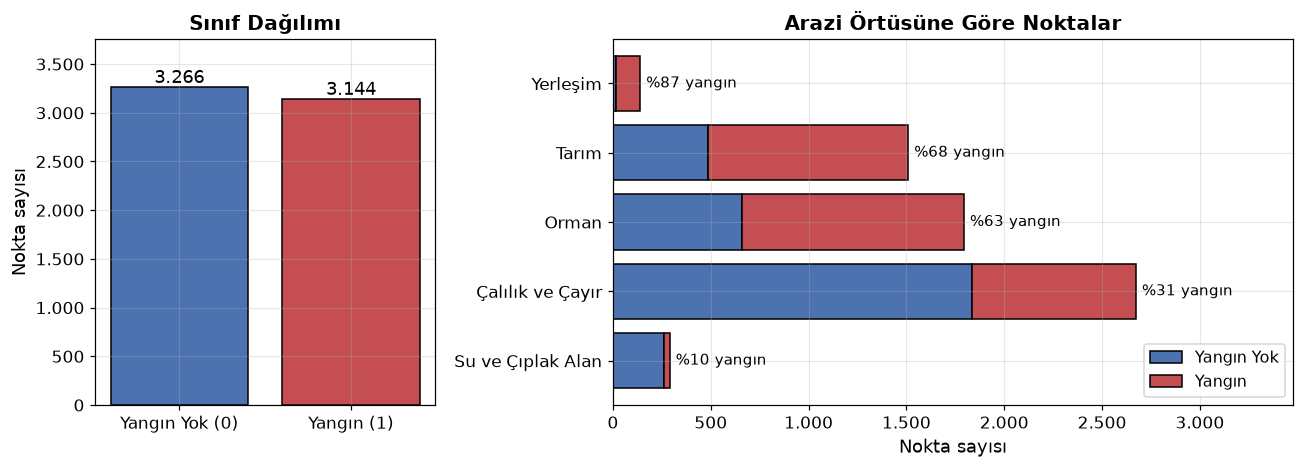

In [3]:
sayim = df["Sinif"].value_counts().reindex(o.SINIF_ETIKETLERI)
print(sayim.to_string())
print()
arazi = (df.groupby("Arazi").agg(Nokta=("Yangin", "size"), Yangin=("Yangin", "sum"),
                                 Yangin_Orani=("Yangin", "mean"))
           .sort_values("Yangin_Orani", ascending=False))
print(arazi.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.bar(o.SINIF_ACIKLAMA, sayim.values, color=["#4c72b0", "#c44e52"], edgecolor="k")
for i, v in enumerate(sayim.values):
    ax.text(i, v + 40, o.tam(v), ha="center")
ax.set_ylabel("Nokta sayısı")
ax.set_title("Sınıf Dağılımı")
ax.set_ylim(0, sayim.max() * 1.15)
ax = axes[1]
y = np.arange(len(arazi))
ax.barh(y, arazi["Nokta"] - arazi["Yangin"], color="#4c72b0", edgecolor="k", label="Yangın Yok")
ax.barh(y, arazi["Yangin"], left=arazi["Nokta"] - arazi["Yangin"], color="#c44e52", edgecolor="k", label="Yangın")
for i, (n, r) in enumerate(zip(arazi["Nokta"], arazi["Yangin_Orani"])):
    ax.text(n + 30, i, f"%{r * 100:.0f} yangın", va="center", fontsize=10)
ax.set_yticks(y)
ax.set_yticklabels(arazi.index)
ax.invert_yaxis()
ax.set_xlabel("Nokta sayısı")
ax.set_xlim(0, arazi["Nokta"].max() * 1.3)
ax.set_title("Arazi Örtüsüne Göre Noktalar")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_hedef_sinif.png"), bbox_inches="tight")
plt.show()
EK["arazi_tablo"] = {k: {"nokta": int(r.Nokta), "yangin": int(r.Yangin), "oran": float(r.Yangin_Orani)}
                     for k, r in arazi.iterrows()}

## 3. Tanımlayıcı İstatistikler

In [4]:
tanim = df[o.SAYISAL].describe().T
tanim["çarpıklık"] = df[o.SAYISAL].skew()
print(tanim.round(3).to_string())
EK["tanim"] = {c: {k: float(v) for k, v in tanim.loc[c].items()} for c in o.SAYISAL}

                   count      mean       std     min      25%       50%       75%        max  çarpıklık
Yukseklik         6410.0   751.161   653.854  -1.000  179.000   573.000  1241.974   2928.000      0.776
Egim              6410.0    14.644     9.337   0.000    7.152    13.521    20.840     66.943      0.637
Sicaklik          6410.0    17.330     2.292  11.120   16.025    17.699    19.060     21.892     -0.782
Yagis             6410.0    69.185    17.917  28.351   55.601    65.188    79.613    129.993      0.729
Ruzgar_Hizi       6410.0     2.181     0.767   0.827    1.792     1.951     2.339      7.683      3.195
NDVI              6410.0     0.181     0.087  -0.480    0.114     0.185     0.245      0.697     -0.030
Yol_Uzaklik       6410.0   670.267   895.086   0.048   87.578   319.582   885.194   7983.795      2.523
Yerlesim_Uzaklik  6410.0  3219.423  3344.285   0.000  975.603  2132.252  4066.075  18816.120      1.930
Akarsu_Uzaklik    6410.0   825.241   736.524   0.088  308.352   

## 4. Sayısal Etkenlerin Sınıflara Göre Dağılımı

Her etken için yangın noktaları ile yangın olmayan noktaların dağılımı karşılaştırılır.
İki dağılım ne kadar ayrışıyorsa etken o kadar bilgilendiricidir. Ayrışmanın büyüklüğü,
etkenin tek başına yangın noktalarını ne kadar iyi sıraladığını gösteren **tek değişkenli
AUC** ile de ölçülür (0,5 = hiç ayırt edemez, 1 = kusursuz ayırır; 0,5'in altındaki
değerler etkenin ters yönde çalıştığını gösterir).

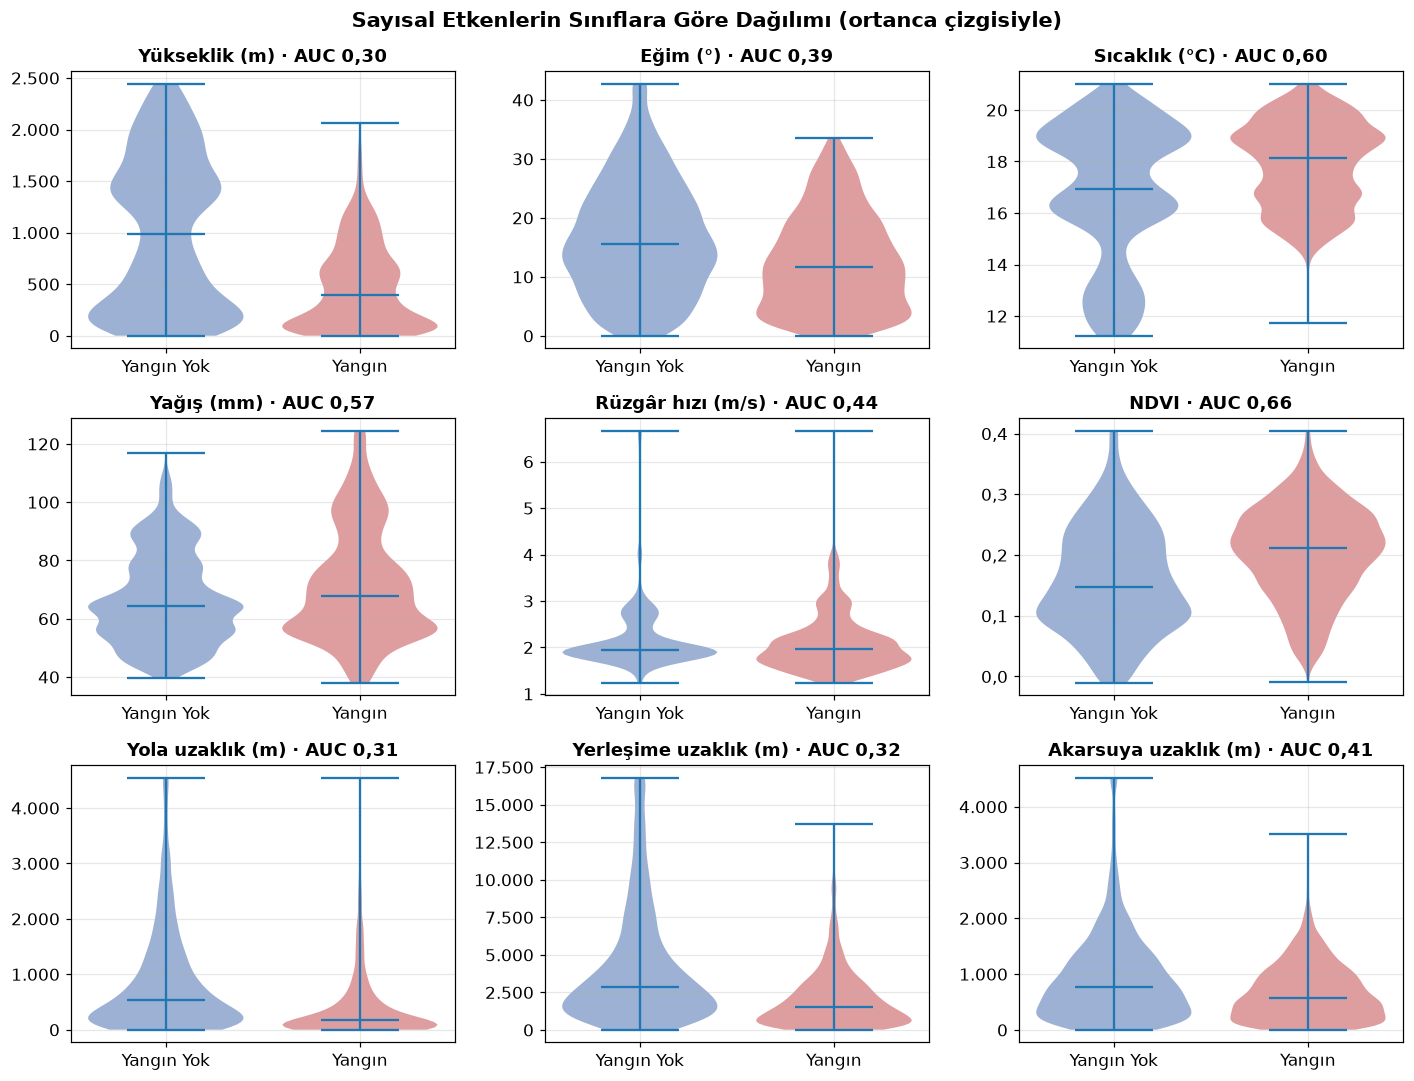

Sinif             Yangın Yok    Yangın  tek değişkenli AUC
Yukseklik            986.500   391.177               0.295
Yol_Uzaklik          529.123   171.073               0.309
Yerlesim_Uzaklik    2880.001  1520.275               0.315
Egim                  15.532    11.660               0.385
Akarsu_Uzaklik       762.049   575.149               0.412
Ruzgar_Hizi            1.950     1.956               0.442
Yagis                 64.296    67.729               0.571
Sicaklik              16.947    18.145               0.599
NDVI                   0.148     0.212               0.661


In [5]:
from sklearn.metrics import roc_auc_score
tek_auc = {c: float(roc_auc_score(df[o.HEDEF], df[c])) for c in o.SAYISAL}
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), o.SAYISAL):
    veri = [df.loc[df[o.HEDEF] == k, c] for k in (0, 1)]
    alt, ust = df[c].quantile(0.005), df[c].quantile(0.995)
    parca = ax.violinplot([v.clip(alt, ust) for v in veri], showmedians=True, widths=0.8)
    for govde, renk in zip(parca["bodies"], ["#4c72b0", "#c44e52"]):
        govde.set_facecolor(renk); govde.set_alpha(0.55)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Yangın Yok", "Yangın"])
    birim = f" ({o.BIRIM[c]})" if o.BIRIM[c] else ""
    ax.set_title(f"{o.OKUNUR[c]}{birim} · AUC {o.sayi(tek_auc[c], 2)}", fontsize=12)
fig.suptitle("Sayısal Etkenlerin Sınıflara Göre Dağılımı (ortanca çizgisiyle)", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_dagilimlar.png"), bbox_inches="tight")
plt.show()
ortanca = df.groupby("Sinif", observed=True)[o.SAYISAL].median().T
ortanca["tek değişkenli AUC"] = pd.Series(tek_auc)
print(ortanca.round(3).sort_values("tek değişkenli AUC").to_string())
EK["tek_auc"] = tek_auc

## 5. Bakı

Bakı, yamacın baktığı yöndür. Kuzey yarımkürede güneye bakan yamaçlar daha çok güneş
alır, daha sıcak ve kuru olur; bu yüzden yangına daha yatkın olmaları beklenir. Bakı
dairesel bir değişken olduğu için (kuzey ile kuzeybatı birbirine yakındır, 0° ile 315°
sayısal olarak uzak görünse de) modellerde sin ve cos bileşenleriyle kodlanmıştır.

            mean  size
Baki                  
Kuzey      0.450  1161
Kuzeydoğu  0.468   603
Doğu       0.525   631
Güneydoğu  0.539   623
Güney      0.559   732
Güneybatı  0.514   736
Batı       0.486   623
Kuzeybatı  0.457   685
Düz        0.437   616


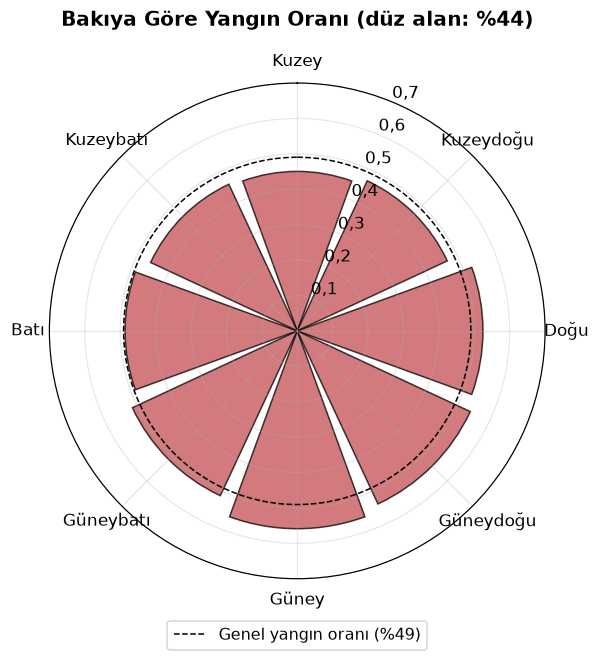

In [6]:
YON = ["Kuzey", "Kuzeydoğu", "Doğu", "Güneydoğu", "Güney", "Güneybatı", "Batı", "Kuzeybatı"]
baki = df.groupby("Baki")[o.HEDEF].agg(["mean", "size"])
print(baki.reindex(YON + ["Düz"]).round(3).to_string())
fig = plt.figure(figsize=(6.2, 6.2))
ax = fig.add_subplot(projection="polar")
aci = np.deg2rad(np.arange(0, 360, 45))
oran = baki.reindex(YON)["mean"].values
ax.bar(aci, oran, width=np.deg2rad(40), color="#c44e52", alpha=0.75, edgecolor="k")
ax.plot(np.linspace(0, 2 * np.pi, 200), np.full(200, df[o.HEDEF].mean()), "k--", lw=1,
        label=f"Genel yangın oranı (%{df[o.HEDEF].mean() * 100:.0f})")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_xticks(aci); ax.set_xticklabels(YON)
ax.set_ylim(0, max(0.7, oran.max() + 0.05))
ax.set_title(f"Bakıya Göre Yangın Oranı (düz alan: %{baki.loc['Düz', 'mean'] * 100:.0f})", pad=18)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.16))
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_baki.png"), bbox_inches="tight")
plt.show()
EK["baki_oran"] = {k: float(v) for k, v in baki["mean"].items()}

## 6. Etkenlerle Yangın Oranı Arasındaki İlişki

Her sayısal etken on eşit gruba (ondalık dilim) ayrılır ve her dilimdeki yangın oranı
hesaplanır. Bu grafik, etkilerin yönünü ve doğrusal olup olmadığını gösterir. Doğrusal
olmayan, eşikli ya da tepe yapan ilişkiler, ağaç tabanlı yöntemlerin doğrusal
yöntemlerden neden daha başarılı olacağının ilk işaretidir.

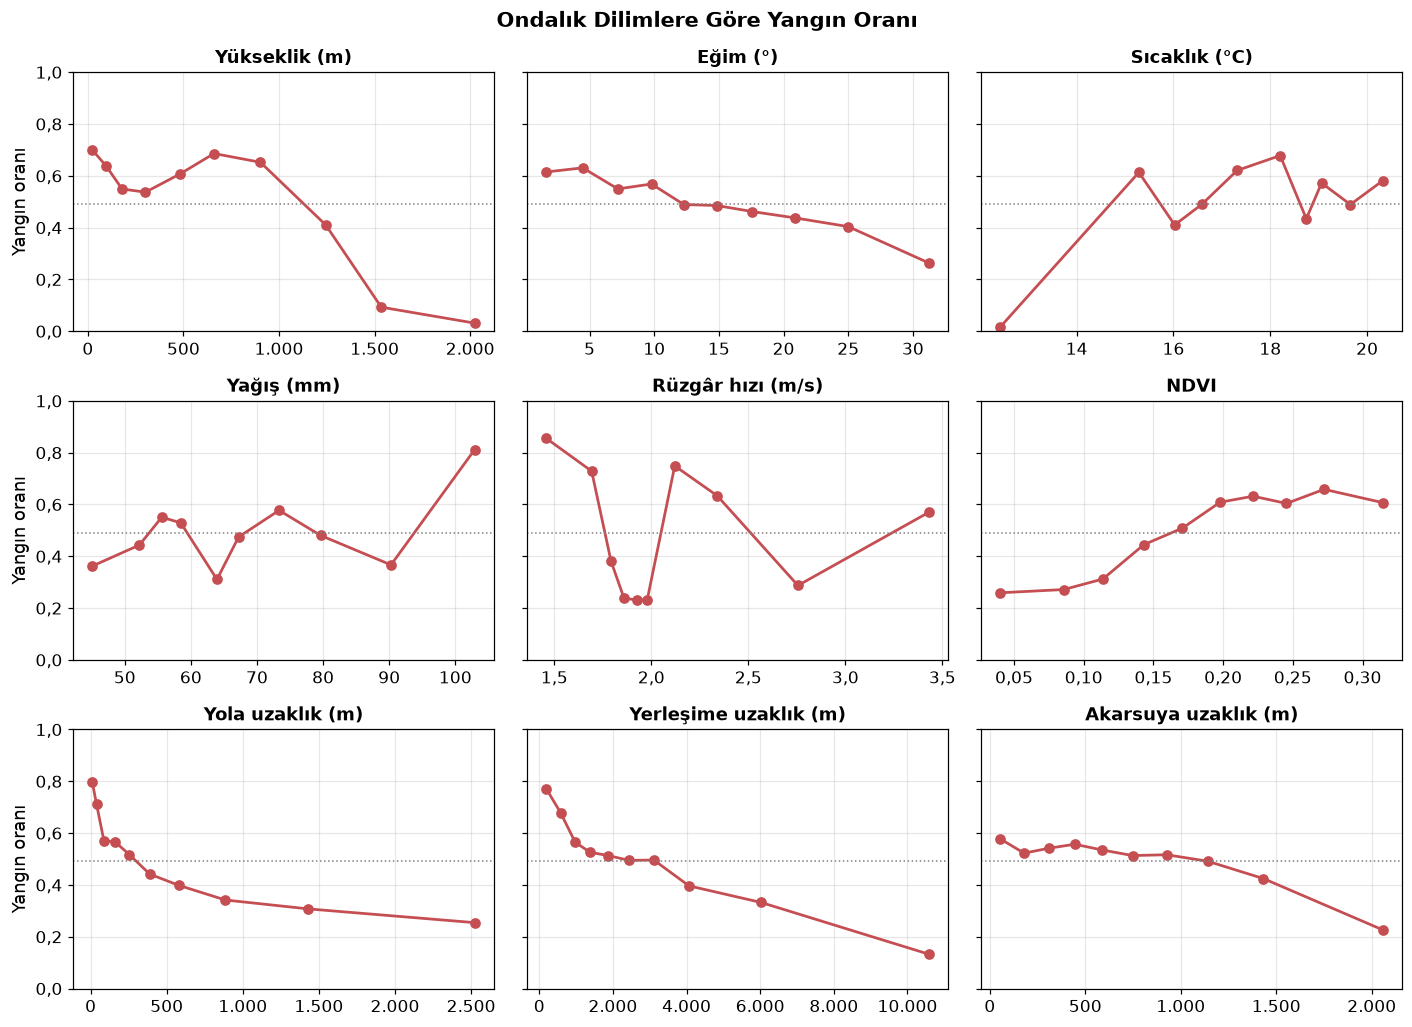

           Yükseklik: en düşük dilim %  70 → en yüksek dilim %   3
                Eğim: en düşük dilim %  61 → en yüksek dilim %  26
            Sıcaklık: en düşük dilim %   2 → en yüksek dilim %  58
               Yağış: en düşük dilim %  36 → en yüksek dilim %  81
         Rüzgâr hızı: en düşük dilim %  85 → en yüksek dilim %  57
                NDVI: en düşük dilim %  26 → en yüksek dilim %  61
        Yola uzaklık: en düşük dilim %  80 → en yüksek dilim %  25
   Yerleşime uzaklık: en düşük dilim %  77 → en yüksek dilim %  13
    Akarsuya uzaklık: en düşük dilim %  58 → en yüksek dilim %  23


In [7]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharey=True)
dilim = {}
for ax, c in zip(axes.ravel(), o.SAYISAL):
    q = pd.qcut(df[c], 10, duplicates="drop")
    g = df.groupby(q, observed=True).agg(x=(c, "median"), oran=(o.HEDEF, "mean"))
    ax.plot(g["x"], g["oran"], "o-", color="#c44e52", lw=1.8)
    ax.axhline(df[o.HEDEF].mean(), color="gray", ls=":", lw=1)
    birim = f" ({o.BIRIM[c]})" if o.BIRIM[c] else ""
    ax.set_title(o.OKUNUR[c] + birim, fontsize=12)
    ax.set_ylim(0, 1)
    dilim[c] = {"x": g["x"].round(4).tolist(), "oran": g["oran"].round(4).tolist()}
for ax in axes[:, 0]:
    ax.set_ylabel("Yangın oranı")
fig.suptitle("Ondalık Dilimlere Göre Yangın Oranı", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_etkenler.png"), bbox_inches="tight")
plt.show()
for c in o.SAYISAL:
    print(f"{o.OKUNUR[c]:>20}: en düşük dilim %{dilim[c]['oran'][0] * 100:4.0f} → en yüksek dilim %{dilim[c]['oran'][-1] * 100:4.0f}")
EK["dilim"] = dilim

## 7. Korelasyon Yapısı

Yüksek korelasyonlu özellik çiftleri, doğrusal modellerde katsayıların yorumunu
zorlaştırır (çoklu doğrusallık) ve Naive Bayes'in bağımsızlık varsayımını çiğner. Bu
veri setinde en belirgin bağ yükseklik ile sıcaklık arasındadır: yükseldikçe hava soğur.

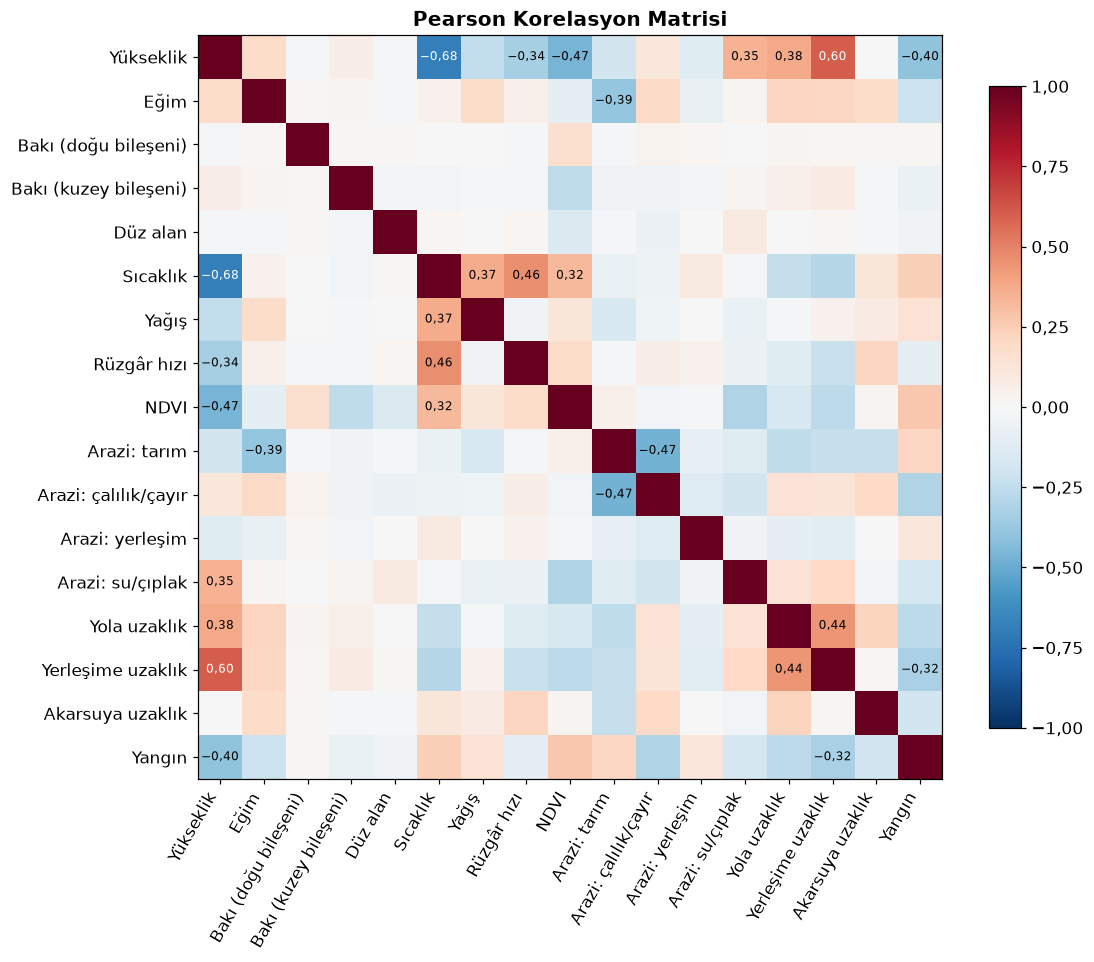

En güçlü 8 ilişki:
Yukseklik    Sicaklik           -0.680
             Yerlesim_Uzaklik    0.603
Arazi_Tarim  Arazi_Calilik      -0.470
Yukseklik    NDVI               -0.465
Sicaklik     Ruzgar_Hizi         0.464
Yol_Uzaklik  Yerlesim_Uzaklik    0.438
Yukseklik    Yangin             -0.401
Egim         Arazi_Tarim        -0.390

Hedefle korelasyon:
Yukseklik          -0.401
Yerlesim_Uzaklik   -0.321
Arazi_Calilik      -0.300
NDVI                0.267
Yol_Uzaklik        -0.260
Sicaklik            0.238
Egim               -0.213
Arazi_Tarim         0.208
Akarsu_Uzaklik     -0.194
Arazi_Su_Ciplak    -0.172
Yagis               0.148
Arazi_Yerlesim      0.114
Ruzgar_Hizi        -0.089
Baki_Cos           -0.069
Baki_Duz           -0.035
Baki_Sin            0.020


In [8]:
kor = df[o.OZELLIKLER + [o.HEDEF]].corr()
etiket = [o.OKUNUR[c] for c in kor.columns]
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(kor.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiket))); ax.set_xticklabels(etiket, rotation=60, ha="right")
ax.set_yticks(range(len(etiket))); ax.set_yticklabels(etiket)
for i in range(len(etiket)):
    for j in range(len(etiket)):
        v = kor.values[i, j]
        if abs(v) >= 0.3 and i != j:
            ax.text(j, i, o.sayi(v, 2), ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
ax.set_title("Pearson Korelasyon Matrisi")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_korelasyon.png"), bbox_inches="tight")
plt.show()
ust = kor.where(np.triu(np.ones(kor.shape, bool), 1)).stack().sort_values(key=np.abs, ascending=False)
print("En güçlü 8 ilişki:")
print(ust.head(8).round(3).to_string())
print()
print("Hedefle korelasyon:")
print(kor[o.HEDEF].drop(o.HEDEF).sort_values(key=np.abs, ascending=False).round(3).to_string())
EK["korelasyon_hedef"] = {k: float(v) for k, v in kor[o.HEDEF].drop(o.HEDEF).items()}
EK["korelasyon_en_guclu"] = [[a, b, float(v)] for (a, b), v in ust.head(8).items()]

## 8. Sözde Mekânsal İklim Grupları

Veri setinde koordinat yoktur. Ancak sıcaklık, yağış ve rüzgâr değerleri meteoroloji
istasyonlarının ölçümlerinden **enterpolasyonla** üretilmiş düzgün yüzeylerden okunmuştur;
birbirine yakın noktalar neredeyse aynı iklim değerlerini taşır. Bu nedenle bir noktanın
iklim değerleri, konumunun bir "parmak izi" gibi davranır. Noktalar bu üç değişkene göre
k-ortalamalar yöntemiyle 25 gruba ayrılmıştır (`_builder/veri_hazirla.py`). Her grup
yaklaşık bir bölgeye karşılık gelir. Grupların çoğunda yangın oranı genel ortalamadan
belirgin biçimde sapar: yangınlar mekânda kümelenmiştir.

İklim uzayında en yakın komşusu aynı sınıfta olan nokta oranı: %95.6
Yangın oranı %80'in üstünde ya da %20'nin altında olan grup oranı: %36
             Nokta  Yangin_Orani  Sicaklik    Yagis
Iklim_Grubu                                        
1              377         0.008    11.906   45.398
2              344         0.029    13.318   51.936
3               87         1.000    14.967  122.105
4              151         0.848    15.372   45.658
5              372         0.449    15.456   60.790
6              141         0.688    16.103   89.943
7              327         0.349    16.152   70.190
8              174         0.546    16.404   78.567
9              199         0.678    16.571  104.993
10             455         0.233    16.694   63.409
11             312         0.949    16.732   49.654
12             199         0.729    17.661   76.727
13             450         0.640    18.012   64.225
14             215         0.679    18.515   56.500
15             319         0

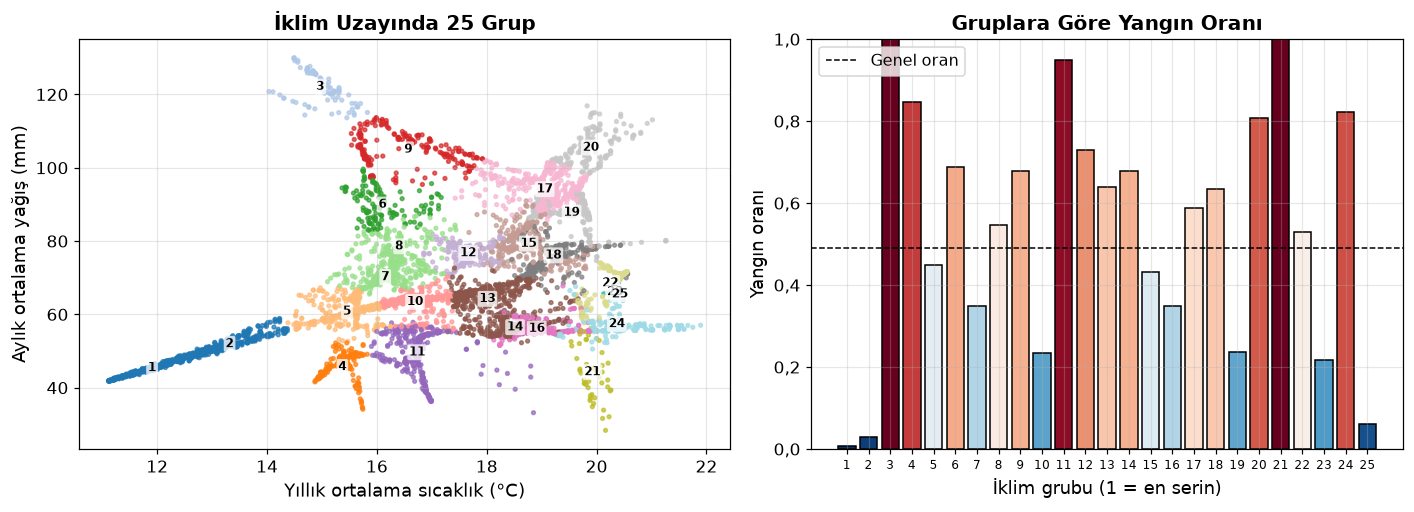

In [9]:
grup = df.groupby(o.GRUP).agg(Nokta=(o.HEDEF, "size"), Yangin_Orani=(o.HEDEF, "mean"),
                               Sicaklik=("Sicaklik", "mean"), Yagis=("Yagis", "mean"))
from sklearn.neighbors import NearestNeighbors
z = (df[o.IKLIM] - df[o.IKLIM].mean()) / df[o.IKLIM].std()
_, komsu = NearestNeighbors(n_neighbors=2).fit(z).kneighbors(z)
ayni_sinif = float((df[o.HEDEF].values[komsu[:, 1]] == df[o.HEDEF].values).mean())
saf = float(((grup.Yangin_Orani >= 0.8) | (grup.Yangin_Orani <= 0.2)).mean())
print(f"İklim uzayında en yakın komşusu aynı sınıfta olan nokta oranı: %{ayni_sinif * 100:.1f}")
print(f"Yangın oranı %80'in üstünde ya da %20'nin altında olan grup oranı: %{saf * 100:.0f}")
print(grup.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
sc = ax.scatter(df["Sicaklik"], df["Yagis"], c=df[o.GRUP], cmap="tab20", s=6, alpha=0.7)
for g, r in grup.iterrows():
    ax.text(r.Sicaklik, r.Yagis, str(g), fontsize=8, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.75, lw=0))
ax.set_xlabel("Yıllık ortalama sıcaklık (°C)")
ax.set_ylabel("Aylık ortalama yağış (mm)")
ax.set_title("İklim Uzayında 25 Grup")
ax = axes[1]
renk = plt.cm.RdBu_r(grup.Yangin_Orani.values)
ax.bar(grup.index.astype(str), grup.Yangin_Orani, color=renk, edgecolor="k")
ax.axhline(df[o.HEDEF].mean(), color="k", ls="--", lw=1, label="Genel oran")
ax.set_xlabel("İklim grubu (1 = en serin)")
ax.set_ylabel("Yangın oranı")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelsize=8)
ax.set_title("Gruplara Göre Yangın Oranı")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_iklim_gruplari.png"), bbox_inches="tight")
plt.show()
EK["grup"] = {"ayni_sinif_komsu": ayni_sinif, "saf_grup_orani": saf,
              "oran_min": float(grup.Yangin_Orani.min()), "oran_max": float(grup.Yangin_Orani.max()),
              "boyut_min": int(grup.Nokta.min()), "boyut_max": int(grup.Nokta.max())}

## 9. Bölünme Seçiminin Gerekçesi: Rastgele ve Sözde Mekânsal Bölünme

Rastgele bir %80/%20 bölünmesinde, bir test noktasının iklim grubundaki "kardeş"
noktalar eğitimde kalır. Model, test noktasını bölgesinden tanıyarak doğru bilebilir;
bu, modelin yeni bir bölgede ne kadar başarılı olacağını söylemez. Bunu sayısal olarak
göstermek için aynı model (LightGBM, varsayılan ayarlar) üç farklı özellik kümesiyle iki
farklı doğrulama düzeninde (5 katlı rastgele ve 5 katlı sözde mekânsal grup) sınanmıştır.
İki düzen arasındaki fark, rastgele bölünmenin sonuçları ne kadar şişirdiğini gösterir.
Kitapta ana sonuçlar alanyazınla karşılaştırılabilirlik için rastgele bölünmeyle verilir,
her algoritmanın güvenilirlik sınaması ise sözde mekânsal grup doğrulamasıyla yapılır.

Tüm özellikler (16)    rastgele AUC = 0.9805 · sözde mekânsal AUC = 0.8795 · fark = +0.1010


İklim hariç (13)       rastgele AUC = 0.8942 · sözde mekânsal AUC = 0.8280 · fark = +0.0662


Yalnız iklim (3)       rastgele AUC = 0.9744 · sözde mekânsal AUC = 0.7665 · fark = +0.2080


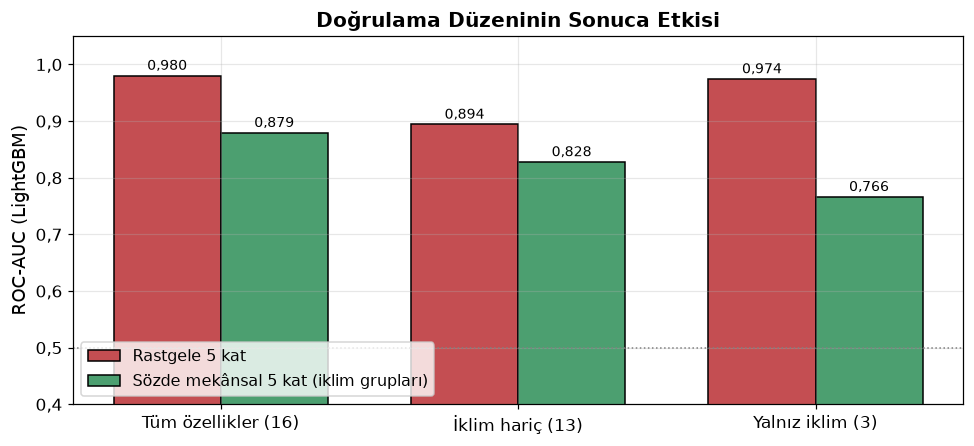

In [10]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold

kumeler = {"Tüm özellikler (16)": o.OZELLIKLER,
           "İklim hariç (13)": [c for c in o.OZELLIKLER if c not in o.IKLIM],
           "Yalnız iklim (3)": o.IKLIM}
rastgele_kat = list(StratifiedKFold(5, shuffle=True, random_state=42).split(df, df[o.HEDEF]))
grup_kat = [(df.index.get_indexer(a), df.index.get_indexer(b)) for a, b in o.grup_katlari(df)]
sizinti = {}
for ad, oz in kumeler.items():
    sonuc = {}
    for duzen, katlar in (("rastgele", rastgele_kat), ("grup", grup_kat)):
        auc = []
        for a, b in katlar:
            m = LGBMClassifier(random_state=42, verbose=-1).fit(df[oz].iloc[a], df[o.HEDEF].iloc[a])
            auc.append(roc_auc_score(df[o.HEDEF].iloc[b], m.predict_proba(df[oz].iloc[b])[:, 1]))
        sonuc[duzen] = float(np.mean(auc))
    sizinti[ad] = sonuc
    print(f"{ad:22s} rastgele AUC = {sonuc['rastgele']:.4f} · sözde mekânsal AUC = {sonuc['grup']:.4f} · "
          f"fark = {sonuc['rastgele'] - sonuc['grup']:+.4f}")
EK["sizinti"] = sizinti

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(sizinti)); w = 0.36
ax.bar(x - w / 2, [v["rastgele"] for v in sizinti.values()], w, label="Rastgele 5 kat", color="#c44e52", edgecolor="k")
ax.bar(x + w / 2, [v["grup"] for v in sizinti.values()], w, label="Sözde mekânsal 5 kat (iklim grupları)", color="#4c9f70", edgecolor="k")
for i, v in enumerate(sizinti.values()):
    ax.text(i - w / 2, v["rastgele"] + 0.01, o.sayi(v['rastgele'], 3), ha="center", fontsize=9)
    ax.text(i + w / 2, v["grup"] + 0.01, o.sayi(v['grup'], 3), ha="center", fontsize=9)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xticks(x); ax.set_xticklabels(list(sizinti.keys()))
ax.set_ylabel("ROC-AUC (LightGBM)")
ax.set_ylim(0.4, 1.05)
ax.set_title("Doğrulama Düzeninin Sonuca Etkisi")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_sizinti.png"), bbox_inches="tight")
plt.show()

## 10. Eğitim/Test Bölünmesi ve Taban Çizgileri

Aşağıdaki değerler, kitap boyunca başvurulacak ölçütlerdir. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı, "karar kütüğü"); bir modelin
işe yaradığını söyleyebilmek için asıl geçilmesi gereken çizgi budur.

In [11]:
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print()
print("Eğitim kümesi sınıf dağılımı:")
print(yc_tr.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())
print()
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())
print()
tb = o.taban_cizgileri(df)
k = tb["kural"]
print(f"Öğrenilen tek kural: {o.OKUNUR[k['ozellik']]} ≤ {k['esik']:.1f} → yangın oranı {k['sol_oran']:.3f}; "
      f"üstünde → {k['sag_oran']:.3f}")
print("TABAN 1 — çoğunluk sınıfı:", tb["cogunluk_sinifi"])
for kk, v in tb["siniflandirma"].items():
    print(f"    {kk:>14}: {v:.4f}")
print("TABAN 2 — tek kural (sınıflandırma)")
for kk, v in tb["kural_siniflandirma"].items():
    print(f"    {kk:>14}: {v:.4f}")
print(f"TABAN 3 — eğitim kümesinin yangın oranı ({tb['egitim_yangin_orani']:.4f})")
for kk, v in tb["regresyon"].items():
    print(f"    {kk:>6}: {v:.4f}")
print("TABAN 4 — tek kural (duyarlılık skoru)")
for kk, v in tb["kural_regresyon"].items():
    print(f"    {kk:>6}: {v:.4f}")
EK["taban"] = tb
EK["test_yangin_orani"] = float(yr_te.mean())

Eğitim: 5128 nokta  |  Test: 1282 nokta

Eğitim kümesi sınıf dağılımı:
Sinif
Yangın Yok    2613
Yangın        2515

Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629

Öğrenilen tek kural: Yükseklik ≤ 1258.0 → yangın oranı 0.622; üstünde → 0.084
TABAN 1 — çoğunluk sınıfı: Yangın Yok
          Accuracy: 0.5094
       BalancedAcc: 0.5000
          F1_macro: 0.3375
       F1_weighted: 0.3438
TABAN 2 — tek kural (sınıflandırma)
          Accuracy: 0.6934
       BalancedAcc: 0.6982
          F1_macro: 0.6748
       F1_weighted: 0.6733
TABAN 3 — eğitim kümesinin yangın oranı (0.4904)
       MAE: 0.4998
       MSE: 0.2499
      RMSE: 0.4999
        R2: -0.0000
       AUC: 0.5000
TABAN 4 — tek kural (duyarlılık skoru)
       MAE: 0.3931
       MSE: 0.1978
      RMSE: 0.4447
        R2: 0.2086
       AUC: 0.6982


In [12]:
ozet = o.sozluk_json_yaz(df, ek=EK)
print("Kitap metnindeki veri bölümü bu dosyadan beslenir.")

Veri özeti kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\_veri_ozeti.json
Kitap metnindeki veri bölümü bu dosyadan beslenir.
